<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week5/lesson17/Lesson17_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 17 — Random Variables and Variability: Distributions, Moments, CV and Fano Factor

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 5 — Probability\
**Lesson:** Lesson 17\
**Notebook type:** Teaching notebook

> *"Two neurons can fire at exactly the same average rate and still be completely different neurons."*

---

### From events to numbers

Lesson 16 worked with **events**: statements that are true or false on each trial. Most neural data are **numbers**: how many spikes fell in a window, how long the gap between two spikes was. A **random variable** attaches a number to each outcome, and its **distribution** says how probable each value is.

We will see:
1. random variables, and how their distributions are described: **probability mass functions** (PMF) for counts, **probability density functions** (PDF) for continuous quantities, and **cumulative distribution functions** (CDF) for both;
2. **expectation**, variance, standard deviation and higher moments, and why $E[g(X)] \ne g(E[X])$ in general;
3. how linear and nonlinear **transformations** change a distribution, and **standardisation**;
4. **covariance**, and why the variance of a population's summed activity depends on it;
5. the two standard measures of spiking variability: the **coefficient of variation** (CV) of interspike intervals and the **Fano factor** of spike counts;
6. **sampling variability**: every statistic computed from data varies from experiment to experiment.

The mini-lab measures variability in two real datasets: spike times from four primate retinal ganglion cells ([Uzzell & Chichilnisky, 2004](https://doi.org/10.1152/jn.01171.2003)), and spike counts across repeated trials from a mouse Neuropixels session ([Steinmetz et al., 2019](https://doi.org/10.1038/s41586-019-1787-x)).

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-16.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']
LINESTYLES = ['-', '--', ':', '-.']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Sliders are pre-computed frames, so they work offline and in a static viewer.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-16.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation and Retrieval: Same Mean, Different Neurons**

Two neurons are recorded for five 200 ms windows. Their spike counts are

$$A: (3, 5, 4, 4, 4),\qquad B: (0, 9, 1, 8, 2).$$

- Both have mean count $\bar x = 20/5 = 4$ spikes per window (20 spikes/s).
- Neuron A: deviations from the mean $(-1, 1, 0, 0, 0)$, sum of squares $2$, sample variance $2/(5 - 1) = 0.5$ spikes².
- Neuron B: deviations $(-4, 5, -3, 4, -2)$, sum of squares $70$, sample variance $70/4 = 17.5$ spikes².

**Prediction before running:** the variance of B is 35 times larger. Dividing each variance by the mean gives the **Fano factor**, $0.125$ for A and $4.375$ for B. A neuron that fires "at random" (a Poisson process, Lesson 18) has a Fano factor of 1. Which neuron is more regular than random, and which more variable?

A is far more regular than random; B is bursty. The mean alone cannot tell them apart, which is why this lesson is about describing **whole distributions** and their spread.

In [3]:
A_counts = np.array([3, 5, 4, 4, 4]); B_counts = np.array([0, 9, 1, 8, 2])      # (5,) spikes per 200 ms window
for name, x in [('A', A_counts), ('B', B_counts)]:
    print(f"neuron {name}: mean {x.mean():.1f} spikes, sample variance {x.var(ddof=1):.2f} spikes^2, Fano factor {x.var(ddof=1) / x.mean():.3f}")

neuron A: mean 4.0 spikes, sample variance 0.50 spikes^2, Fano factor 0.125
neuron B: mean 4.0 spikes, sample variance 17.50 spikes^2, Fano factor 4.375


# **Part 1: Random Variables, PMFs and CDFs**

A **random variable** $X$ is a rule that assigns a number to each outcome of an experiment. Upper-case $X$ is the variable; lower-case $x$ is a particular value it can take. Each statement about $X$ is an event, such as $\{X = 2\}$ or $\{X \le 2\}$, so Lesson 16's rules apply.

- $X$ is **discrete** if it takes separated values (spike counts, number of vesicles released, number of correct trials).
- $X$ is **continuous** if it takes values in an interval (an interspike interval, a membrane potential, a reaction time).

A discrete $X$ is described by its **probability mass function** (PMF),

$$p_X(k) = P(X = k),\qquad p_X(k) \ge 0,\qquad \sum_k p_X(k) = 1,$$

and every random variable by its **cumulative distribution function** (CDF),

$$F_X(x) = P(X \le x).$$

$F_X$ never decreases, rises from 0 to 1, and for a discrete $X$ is a **step function** that jumps by $p_X(k)$ at each value $k$. Probabilities of ranges come straight from it: $P(a < X \le b) = F_X(b) - F_X(a)$. The **median** is the smallest $x$ with $F_X(x) \ge 0.5$; more generally the $q$-quantile is the smallest $x$ with $F_X(x) \ge q$.

**Example.** At a synapse with four release sites, the number of vesicles released by one action potential, $X \in \{0, 1, 2, 3, 4\}$, has the PMF below (an invented but realistic table).

k:      [0 1 2 3 4]
P(X=k): [0.24 0.41 0.26 0.08 0.01]
F(k):   [0.24 0.65 0.91 0.99 1.  ]
P(X >= 2) = 1 - F(1) = 0.35;  P(1 < X <= 3) = F(3) - F(1) = 0.34;  median = 1
empirical PMF from 500 simulated action potentials: [0.256 0.394 0.266 0.078 0.006]


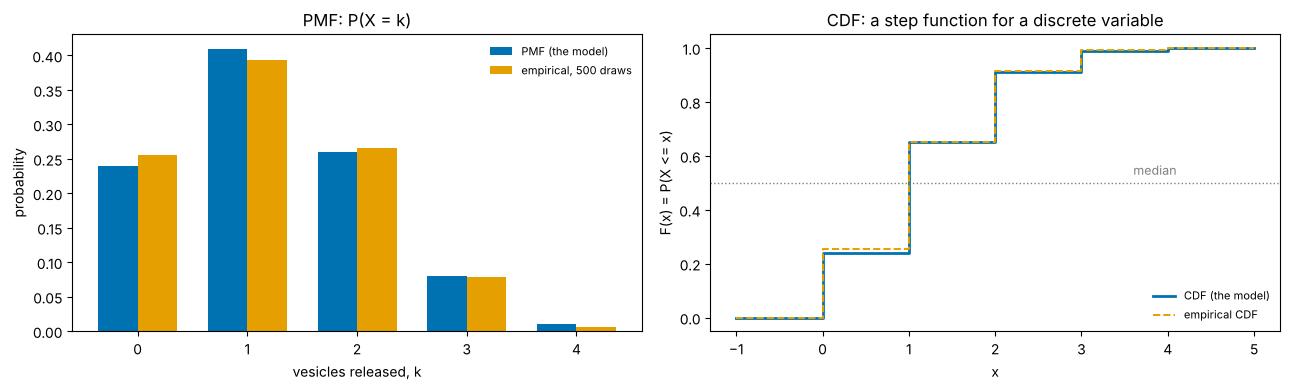

In [4]:
k_vals = np.arange(5)                                                       # (5,) possible numbers of vesicles
pmf = np.array([0.24, 0.41, 0.26, 0.08, 0.01])                              # (5,) P(X = k)
assert np.all(pmf >= 0) and np.isclose(pmf.sum(), 1), "a PMF must be non-negative and sum to 1"
cdf = np.cumsum(pmf)                                                        # (5,) F(k) = P(X <= k)
print("k:     ", k_vals); print("P(X=k):", pmf); print("F(k):  ", np.round(cdf, 2))
print(f"P(X >= 2) = 1 - F(1) = {1 - cdf[1]:.2f};  P(1 < X <= 3) = F(3) - F(1) = {cdf[3] - cdf[1]:.2f};  median = {k_vals[np.argmax(cdf >= 0.5)]}")

releases = RNG.choice(k_vals, size=500, p=pmf)                              # (500,) simulated action potentials
emp_pmf = np.bincount(releases, minlength=5) / releases.size                # (5,) empirical PMF
print("empirical PMF from 500 simulated action potentials:", np.round(emp_pmf, 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(k_vals - 0.18, pmf, width=0.36, color=PALETTE[0], label='PMF (the model)')
axes[0].bar(k_vals + 0.18, emp_pmf, width=0.36, color=PALETTE[4], label='empirical, 500 draws')
axes[0].set_xlabel('vesicles released, k'); axes[0].set_ylabel('probability'); axes[0].set_title('PMF: P(X = k)'); axes[0].legend(fontsize=8, frameon=False)
xs_step = np.r_[-1, k_vals, 5]
axes[1].step(xs_step, np.r_[0, cdf, 1], where='post', color=PALETTE[0], lw=2, label='CDF (the model)')
srt = np.sort(releases)
axes[1].step(np.r_[-1, srt, 5], np.r_[0, np.arange(1, srt.size + 1) / srt.size, 1], where='post', color=PALETTE[4], lw=1.4, ls='--', label='empirical CDF')
axes[1].axhline(0.5, color='grey', ls=':', lw=1); axes[1].text(3.6, 0.53, 'median', color='grey', fontsize=9)
axes[1].set_xlabel('x'); axes[1].set_ylabel('F(x) = P(X <= x)'); axes[1].set_title('CDF: a step function for a discrete variable'); axes[1].legend(fontsize=8, frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

The CDF is defined for **every** real $x$, not only at the possible values: $F(1.7) = F(1) = 0.65$, because $X \le 1.7$ means $X \le 1$. The empirical PMF and CDF (the proportions in 500 simulated action potentials) are close to the model but not equal to it: the sampling noise of Lesson 16 again. The **empirical CDF**, the fraction of observations $\le x$, needs no binning choices, which makes it the most honest picture of a sample.

# **Part 2: Continuous Variables, Densities and CDFs**

For a continuous variable, every single value has probability zero: the chance that an interspike interval is *exactly* 20.000… ms is 0. Probabilities belong to **intervals**, and they are given by the **probability density function** (PDF) $f_X$:

$$P(a < X \le b) = \int_a^b f_X(x)\,dx = F_X(b) - F_X(a),\qquad f_X(x) \ge 0,\qquad \int_{-\infty}^{\infty} f_X(x)\,dx = 1.$$

By the Fundamental Theorem of Calculus (Lesson 13), $F_X(x) = \int_{-\infty}^{x} f_X(u)\,du$ and $f_X = F_X'$.

- A density is **not** a probability. Its **units** are 1/(units of $x$): an ISI density is in "per millisecond", and $f_X(x)\,\Delta x$ is approximately the probability of a small interval of width $\Delta x$.
- A density can therefore exceed 1. Changing units from ms to s multiplies every density value by 1000.
- A histogram estimates a density only when it is normalised so that its **area** is 1 (`density=True` in Matplotlib and NumPy): bar height = count / ($n \times$ bin width).

**Example: an interval density with a refractory period.** A model neuron cannot fire again within $\tau = 2$ ms of a spike; after that, the chance of firing per unit time is constant, $\lambda = 0.05$ per ms. Its interspike interval $T$ has density and CDF

$$f_T(t) = \lambda\,e^{-\lambda(t - \tau)}\ \ (t \ge \tau),\qquad f_T(t) = 0\ \ (t < \tau);\qquad F_T(t) = 1 - e^{-\lambda(t - \tau)}\ \ (t \ge \tau).$$

(Without the refractory shift this is the exponential distribution, which Lesson 18 connects to Poisson spiking.)

area under the density (trapezoid rule, Lesson 13): 1.000025
P(5 < T <= 20 ms) from the CDF: 0.4541;  by integrating the density: 0.4541
density at t = tau: 0.050 per ms = 50 per s  (a density, not a probability)
median ISI: F(m) = 0.5  =>  m = tau + ln(2)/lambda = 15.86 ms


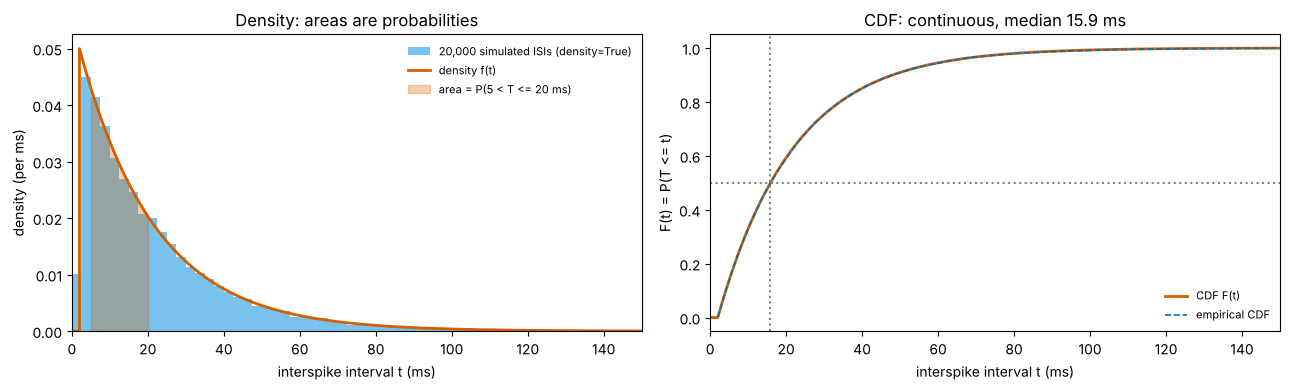

In [5]:
tau_ref, lam = 2.0, 0.05                                                    # refractory period (ms), firing hazard (per ms)
def isi_pdf(t):
    t = np.asarray(t, dtype=float)
    return np.where(t >= tau_ref, lam * np.exp(-lam * (t - tau_ref)), 0.0)     # per ms
def isi_cdf(t):
    t = np.asarray(t, dtype=float)
    return np.where(t >= tau_ref, 1 - np.exp(-lam * (t - tau_ref)), 0.0)

t_grid = np.linspace(0, 400, 400001)                                        # (400001,) ms, step 0.001 ms
print(f"area under the density (trapezoid rule, Lesson 13): {np.trapezoid(isi_pdf(t_grid), t_grid):.6f}")
print(f"P(5 < T <= 20 ms) from the CDF: {isi_cdf(20) - isi_cdf(5):.4f};  by integrating the density: "
      f"{np.trapezoid(isi_pdf(t_grid[(t_grid >= 5) & (t_grid <= 20)]), t_grid[(t_grid >= 5) & (t_grid <= 20)]):.4f}")
print(f"density at t = tau: {isi_pdf(tau_ref):.3f} per ms = {isi_pdf(tau_ref) * 1000:.0f} per s  (a density, not a probability)")
median_T = tau_ref + np.log(2) / lam
print(f"median ISI: F(m) = 0.5  =>  m = tau + ln(2)/lambda = {median_T:.2f} ms")

# Simulate intervals by the inverse-CDF method: if U is uniform on (0, 1), then F^{-1}(U) has CDF F (Part 4 explains why).
U = RNG.random(20000)
T_sim = tau_ref - np.log(1 - U) / lam                                      # (20000,) simulated ISIs, ms
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.arange(0, 150, 2.5)
axes[0].hist(T_sim, bins=bins, density=True, color=PALETTE[5], alpha=0.8, label='20,000 simulated ISIs (density=True)')
axes[0].plot(t_grid[:150001], isi_pdf(t_grid[:150001]), color=PALETTE[1], lw=2, label='density f(t)')
axes[0].fill_between(t_grid[(t_grid >= 5) & (t_grid <= 20)], isi_pdf(t_grid[(t_grid >= 5) & (t_grid <= 20)]), color=PALETTE[1], alpha=0.3, label='area = P(5 < T <= 20 ms)')
axes[0].set_xlim(0, 150); axes[0].set_xlabel('interspike interval t (ms)'); axes[0].set_ylabel('density (per ms)')
axes[0].set_title('Density: areas are probabilities'); axes[0].legend(fontsize=8, frameon=False)
axes[1].plot(t_grid[:150001], isi_cdf(t_grid[:150001]), color=PALETTE[1], lw=2, label='CDF F(t)')
srtT = np.sort(T_sim)
axes[1].step(srtT, np.arange(1, srtT.size + 1) / srtT.size, where='post', color=PALETTE[0], lw=1.2, ls='--', label='empirical CDF')
axes[1].axhline(0.5, color='grey', ls=':'); axes[1].axvline(median_T, color='grey', ls=':')
axes[1].set_xlim(0, 150); axes[1].set_xlabel('interspike interval t (ms)'); axes[1].set_ylabel('F(t) = P(T <= t)')
axes[1].set_title(f'CDF: continuous, median {median_T:.1f} ms'); axes[1].legend(fontsize=8, frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

The histogram, normalised to area 1, tracks the density; the empirical CDF lies almost on the model CDF. Note the gap below 2 ms (the refractory period) and the long right tail. The shaded area is a probability (0.45); the curve's height at a point is not.

> **Common error.** Reading a histogram's bar heights as probabilities. With `density=True` the heights depend on the bin width and the units; only areas are probabilities. Without it, the heights are counts, which depend on $n$.

# **Part 3: Expectation, Variance and Moments**

The **expectation** (mean) of $X$ is its probability-weighted average value:

$$E[X] = \sum_k k\,p_X(k)\ \ \text{(discrete)},\qquad E[X] = \int x\,f_X(x)\,dx\ \ \text{(continuous)},$$

with the same units as $X$. Two rules do most of the work:
- **Linearity:** $E[aX + bY + c] = aE[X] + bE[Y] + c$, always (no independence needed).
- **Expectation of a function** ("law of the unconscious statistician"): $E[g(X)] = \sum_k g(k)\,p_X(k)$ or $\int g(x) f_X(x)\,dx$; no need to find the distribution of $g(X)$ first.

But **in general $E[g(X)] \ne g(E[X])$** unless $g$ is linear.

The **variance** measures spread around the mean $\mu = E[X]$:

$$\operatorname{Var}(X) = E\big[(X - \mu)^2\big] = E[X^2] - \mu^2,$$

in squared units; the **standard deviation** $\sigma = \sqrt{\operatorname{Var}(X)}$ is back in the units of $X$. More generally, $E[X^m]$ is the $m$-th **moment** and $E[(X - \mu)^m]$ the $m$-th **central moment**. The third central moment divided by $\sigma^3$ is the **skewness**: positive when there is a long right tail, as for interspike intervals, where the mean exceeds the median.

**From data.** The sample mean $\bar x = \frac1n\sum_i x_i$ estimates $\mu$. The sample variance with divisor $n - 1$, $s^2 = \frac{1}{n-1}\sum_i (x_i - \bar x)^2$ (`np.var(x, ddof=1)`), estimates $\sigma^2$ without bias (Part 7 shows why); `np.var(x)` divides by $n$.

In [6]:
# Discrete: the vesicle-release PMF.
EX = np.sum(k_vals * pmf); EX2 = np.sum(k_vals**2 * pmf)
print(f"vesicles: E[X] = {EX:.2f}, E[X^2] = {EX2:.2f}, Var = {EX2 - EX**2:.4f} = E[(X - mu)^2] = {np.sum((k_vals - EX)**2 * pmf):.4f}, SD = {np.sqrt(EX2 - EX**2):.3f} vesicles")
print(f"  500 simulated draws: mean {releases.mean():.3f}, sample variance (ddof=1) {releases.var(ddof=1):.4f}")

# Continuous: the refractory ISI density, by numerical integration.
f_vals = isi_pdf(t_grid)
ET = np.trapezoid(t_grid * f_vals, t_grid); VT = np.trapezoid((t_grid - ET)**2 * f_vals, t_grid)
skew = np.trapezoid((t_grid - ET)**3 * f_vals, t_grid) / VT**1.5
print(f"ISI: E[T] = {ET:.3f} ms (exact tau + 1/lambda = {tau_ref + 1 / lam:.0f}), SD = {np.sqrt(VT):.3f} ms (exact 1/lambda = {1 / lam:.0f}), "
      f"skewness = {skew:.2f} (exact 2);  mean {ET:.1f} > median {median_T:.1f}")
print(f"  20,000 simulated ISIs: mean {T_sim.mean():.2f} ms, SD {T_sim.std(ddof=1):.2f} ms")

# E[g(T)] != g(E[T]): mean of instantaneous rates 1/T versus the rate 1/E[T].
E_inv = np.trapezoid(np.where(t_grid > 0, f_vals / np.maximum(t_grid, 1e-12), 0), t_grid)
print(f"1 / E[T] = {1000 / ET:.1f} spikes/s (the firing rate),  but  E[1/T] = {1000 * E_inv:.1f} spikes/s (average 'instantaneous rate')")
print(f"  simulated: 1/mean(T) = {1000 / T_sim.mean():.1f}/s,  mean(1/T) = {np.mean(1000 / T_sim):.1f}/s")

vesicles: E[X] = 1.21, E[X^2] = 2.33, Var = 0.8659 = E[(X - mu)^2] = 0.8659, SD = 0.931 vesicles
  500 simulated draws: mean 1.184, sample variance (ddof=1) 0.8559
ISI: E[T] = 22.000 ms (exact tau + 1/lambda = 22), SD = 20.000 ms (exact 1/lambda = 20), skewness = 2.00 (exact 2);  mean 22.0 > median 15.9
  20,000 simulated ISIs: mean 22.09 ms, SD 20.26 ms
1 / E[T] = 45.5 spikes/s (the firing rate),  but  E[1/T] = 100.7 spikes/s (average 'instantaneous rate')
  simulated: 1/mean(T) = 45.3/s,  mean(1/T) = 100.7/s


The firing rate of this model neuron is $1/E[T] = 1/22\ \text{ms} \approx 45$ spikes/s, but the average of the "instantaneous rates" $1/T$ is about 101 spikes/s. Short intervals produce huge values of $1/T$ and dominate the average. Because $1/t$ is convex, $E[1/T] \ge 1/E[T]$ always (Jensen's inequality). **Averaging a nonlinear function of a variable is not the same as applying the function to the average**, and in the mini-lab the real retinal cells show this gap at five times the rate.

Note also that $\operatorname{Var} = E[X^2] - \mu^2$ is exact mathematics but can be numerically poor: when $\mu$ is large compared with $\sigma$, it subtracts two nearly equal large numbers. NumPy's `var` uses the centred form.

# **Part 4: Transformations and Standardisation**

### Linear transformations
If $Y = aX + b$, then

$$E[Y] = aE[X] + b,\qquad \operatorname{Var}(Y) = a^2\operatorname{Var}(X),\qquad \operatorname{SD}(Y) = \lvert a\rvert\,\operatorname{SD}(X).$$

Adding a constant shifts the distribution but leaves its spread unchanged; scaling stretches both. Unit changes are linear transformations: a count in a 200 ms window becomes a rate in spikes/s with $a = 5\ \text{s}^{-1}$, so the mean is multiplied by 5 and the variance by 25.

### Standardisation
The **z-score** $Z = (X - \mu)/\sigma$ has mean 0, variance 1 and **no units**. It says how many standard deviations a value lies from the mean, which makes variables in different units comparable (Lessons 7 and 15). With data, $\mu$ and $\sigma$ are replaced by the sample mean and SD, computed from the **training** data only when the z-scores feed a model.

### Nonlinear transformations
For a nonlinear $g$, $E[g(X)]$ and $\operatorname{Var}(g(X))$ must be computed from the distribution of $X$ (Part 3). If $g$ is increasing, the CDF transforms simply:

$$F_{g(X)}(y) = P(g(X) \le y) = P(X \le g^{-1}(y)) = F_X(g^{-1}(y)).$$

Two consequences:
- **Quantiles transform; means do not.** The median of $g(X)$ is $g(\text{median of } X)$ for increasing $g$, but the mean of $g(X)$ is generally not $g(\text{mean})$.
- **Inverse-CDF sampling** (used in Part 2): if $U$ is uniform on $(0, 1)$ and $X = F^{-1}(U)$, then $P(X \le x) = P(U \le F(x)) = F(x)$. Any distribution can be simulated from uniform random numbers.

counts: mean 4.011 spikes, variance 4.068 spikes^2
rates:  mean 20.055 spikes/s (= 5 x 4.011), variance 101.71 (spikes/s)^2 (= 25 x 4.068)
z-scores: mean 1.5e-16, SD 1.000 (unitless); identical whether computed from counts or rates: True

log10 ISI: median 1.2039 = log10(median ISI) 1.2039  (quantiles transform)
           mean   1.1767 vs log10(mean ISI) 1.3441  (means do not)


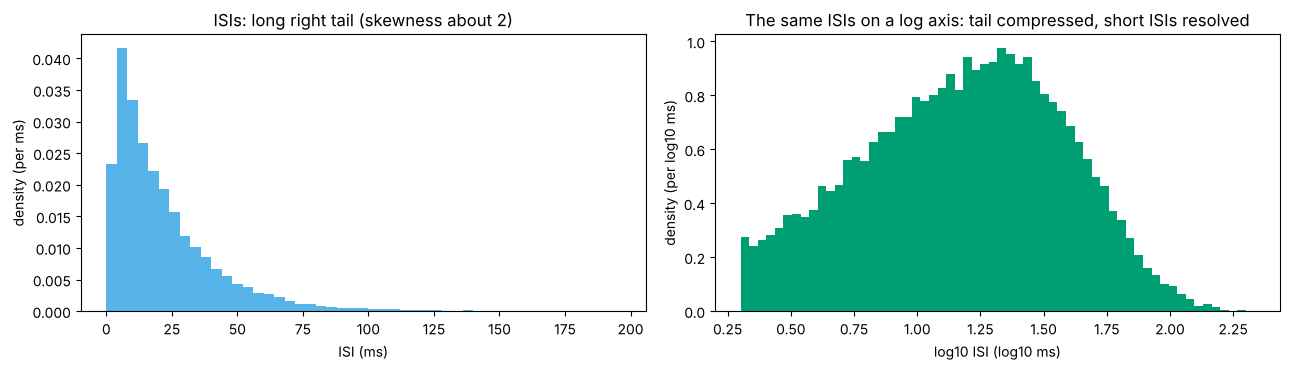

In [7]:
counts_win = RNG.poisson(4.0, size=10000)                                  # (10000,) spikes in a 200 ms window (simulated)
rates_hz = 5.0 * counts_win                                                 # (10000,) spikes/s
print(f"counts: mean {counts_win.mean():.3f} spikes, variance {counts_win.var(ddof=1):.3f} spikes^2")
print(f"rates:  mean {rates_hz.mean():.3f} spikes/s (= 5 x {counts_win.mean():.3f}), variance {rates_hz.var(ddof=1):.2f} (spikes/s)^2 (= 25 x {counts_win.var(ddof=1):.3f})")
z = (rates_hz - rates_hz.mean()) / rates_hz.std(ddof=1)
print(f"z-scores: mean {z.mean():.1e}, SD {z.std(ddof=1):.3f} (unitless); identical whether computed from counts or rates: "
      f"{np.allclose(z, (counts_win - counts_win.mean()) / counts_win.std(ddof=1))}")

logT = np.log10(T_sim)                                                     # log of ISIs (ms)
print(f"\nlog10 ISI: median {np.median(logT):.4f} = log10(median ISI) {np.log10(np.median(T_sim)):.4f}  (quantiles transform)")
print(f"           mean   {logT.mean():.4f} vs log10(mean ISI) {np.log10(T_sim.mean()):.4f}  (means do not)")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(T_sim, bins=np.arange(0, 200, 4), density=True, color=PALETTE[5]); axes[0].set_xlabel('ISI (ms)'); axes[0].set_ylabel('density (per ms)')
axes[0].set_title('ISIs: long right tail (skewness about 2)')
axes[1].hist(logT, bins=60, density=True, color=PALETTE[2]); axes[1].set_xlabel('log10 ISI (log10 ms)'); axes[1].set_ylabel('density (per log10 ms)')
axes[1].set_title('The same ISIs on a log axis: tail compressed, short ISIs resolved')
plt.tight_layout(); plt.show()

The log transform is the standard way to display interspike intervals: it compresses the long tail and spreads out the short intervals where bursts and refractoriness live. The densities on the two panels have different units (per ms, per log$_{10}$ ms) and different shapes, but they describe the same intervals.

# **Part 5: Covariance and the Variance of a Sum**

For two random variables measured on the same trials, the **covariance**

$$\operatorname{Cov}(X, Y) = E\big[(X - \mu_X)(Y - \mu_Y)\big] = E[XY] - \mu_X\mu_Y$$

is positive when $X$ and $Y$ tend to be above their means together, negative when one tends to be above while the other is below. Its units are those of $X$ times those of $Y$; $\operatorname{Cov}(X, X) = \operatorname{Var}(X)$. Dividing by both SDs gives the unitless **correlation** $\rho = \operatorname{Cov}(X, Y)/(\sigma_X\sigma_Y) \in [-1, 1]$ (Lesson 20 studies it in detail). For $p$ variables the covariances form the $p \times p$ **covariance matrix** of Lesson 7.

- If $X$ and $Y$ are independent, $E[XY] = E[X]E[Y]$, so $\operatorname{Cov}(X, Y) = 0$. The converse is false: zero covariance does not imply independence.
- **Variance of a sum:** expanding the square,

$$\operatorname{Var}(X + Y) = \operatorname{Var}(X) + \operatorname{Var}(Y) + 2\operatorname{Cov}(X, Y),\qquad
\operatorname{Var}\Big(\sum_{i=1}^{n} X_i\Big) = \sum_i \operatorname{Var}(X_i) + \sum_{i \ne j}\operatorname{Cov}(X_i, X_j).$$

For $n$ neurons the second sum has $n(n - 1)$ terms, so even **small pairwise covariances dominate the variance of a population's summed activity** when $n$ is large.

In [8]:
# Uncorrelated but dependent: Y is completely determined by X.
x_u = RNG.uniform(-1, 1, 100000); y_u = x_u**2
print(f"X uniform on (-1, 1), Y = X^2:  Cov(X, Y) = {np.cov(x_u, y_u)[0, 1]:+.4f} (exact 0), yet P(Y > 0.25 | |X| > 0.5) = {np.mean(y_u[np.abs(x_u) > 0.5] > 0.25):.0f}")

# 50 neurons whose counts share a trial-to-trial gain fluctuation (for example, the animal's arousal).
n_neur, n_trials = 50, 4000
gain = RNG.gamma(shape=20.0, scale=1 / 20.0, size=(n_trials, 1))           # (4000, 1) shared gain, mean 1, SD about 0.22
base = RNG.uniform(2, 6, size=(1, n_neur))                                  # (1, 50) mean count of each neuron
counts_pop = RNG.poisson(gain * base)                                       # (4000, 50) spike counts
var_each = counts_pop.var(axis=0, ddof=1)                                   # (50,)
cov_mat = np.cov(counts_pop, rowvar=False)                                  # (50, 50); rows of counts_pop are trials
off_diag = cov_mat[~np.eye(n_neur, dtype=bool)]
pop_sum = counts_pop.sum(axis=1)                                            # (4000,) summed population count
print(f"\nmean pairwise covariance {off_diag.mean():.3f} spikes^2 (mean correlation {np.mean(off_diag / np.sqrt(np.outer(var_each, var_each))[~np.eye(n_neur, dtype=bool)]):.3f})")
print(f"sum of the 50 variances {var_each.sum():.0f};  sum of the {n_neur * (n_neur - 1)} covariances {off_diag.sum():.0f};  total {cov_mat.sum():.0f}")
print(f"variance of the summed count {pop_sum.var(ddof=1):.0f}  (= sum of all entries of the covariance matrix: {np.isclose(pop_sum.var(ddof=1), cov_mat.sum())})")

X uniform on (-1, 1), Y = X^2:  Cov(X, Y) = +0.0004 (exact 0), yet P(Y > 0.25 | |X| > 0.5) = 1

mean pairwise covariance 0.809 spikes^2 (mean correlation 0.163)
sum of the 50 variances 245;  sum of the 2450 covariances 1983;  total 2228
variance of the summed count 2228  (= sum of all entries of the covariance matrix: True)


Each pair of neurons is only weakly correlated (correlation about 0.16), yet the 2,450 covariance terms contribute about eight times more to the variance of the summed count than the 50 individual variances. This is why **noise correlations** matter for population coding: they set how much averaging over neurons actually reduces variability. The identity $\operatorname{Var}(\sum_i X_i) = \mathbf{1}^{\mathsf T}\boldsymbol\Sigma\mathbf{1}$ (the sum of every entry of the covariance matrix $\boldsymbol\Sigma$) holds exactly for sample covariances too.

# **Part 6: Spiking Variability: CV and Fano Factor**

Two standard, unitless summaries describe how irregular a spike train is.

**Coefficient of variation of interspike intervals.** For intervals $T_1, T_2, \dots$,

$$\mathrm{CV} = \frac{\operatorname{SD}(T)}{E[T]}.$$

**Fano factor of spike counts.** For counts $N$ in windows of a fixed length $w$ (repeated trials, or successive windows),

$$\mathrm{FF}(w) = \frac{\operatorname{Var}(N)}{E[N]}.$$

Reference values come from the **Poisson process**, in which spikes occur independently at a constant rate (Lesson 18 develops it): its intervals have CV = 1 and its counts have FF = 1 for every window length.
- **CV, FF < 1: more regular than Poisson.** Refractoriness and strong, steady drive make intervals more alike (a clock has CV = 0).
- **CV, FF > 1: more variable than Poisson.** Bursts, slow changes in rate, and shared fluctuations across trials.

Points to remember:
- CV is defined for intervals, FF for counts. The Fano factor of a count is unitless only because counts are pure numbers: **never compute a Fano factor on rates in spikes/s** (rescaling by $a$ multiplies Var/mean by $a$).
- FF depends on the window length $w$. For a **renewal** process (intervals independent and identically distributed), $\mathrm{FF}(w) \to \mathrm{CV}^2$ for long windows.
- CV computed over a whole recording mixes **intrinsic** irregularity with **rate changes** driven by the stimulus or behaviour.

Below, three simulated neurons at the same mean rate (20 spikes/s): a Poisson process, a regular neuron (each interval the sum of 5 exponential stages, a gamma distribution with CV $= 1/\sqrt5 \approx 0.45$), and a bursty neuron (bursts of 2-4 spikes 2-5 ms apart, separated by long gaps).

neuron                     rate (/s)     CV   CV^2   FF at windows 10 ms, 100 ms, 1 s, 5 s


Poisson process                 20.1   1.00   1.00   0.99, 1.00, 1.00, 0.92
regular (gamma, order 5)        19.9   0.45   0.20   0.80, 0.28, 0.20, 0.18
bursty                          19.6   2.13   4.53   1.92, 2.84, 3.16, 3.21


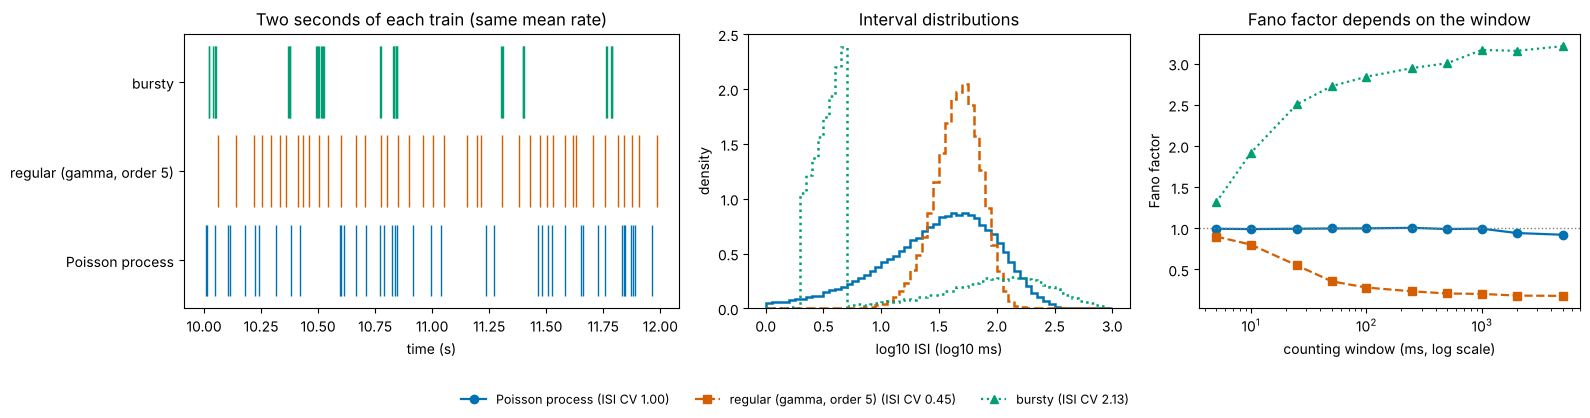

In [9]:
def isi_cv(spike_times):
    # CV of interspike intervals; spike_times is a sorted 1-D array (s). Needs at least 3 spikes.
    isi = np.diff(np.asarray(spike_times, dtype=float))
    if isi.size < 2:
        return np.nan
    return isi.std(ddof=1) / isi.mean()

def fano(spike_times, window, t_start, t_stop):
    # Fano factor of counts in consecutive non-overlapping windows of length `window` (s) between t_start and t_stop.
    edges = np.arange(t_start, t_stop - window + 1e-12, window)
    counts = np.histogram(spike_times, bins=np.r_[edges, edges[-1] + window])[0]
    return counts.var(ddof=1) / counts.mean()

def train_from_isis(isis):
    return np.cumsum(isis)

rate, T_rec = 20.0, 2000.0                                                  # spikes/s, s of simulated recording
n_isi = int(rate * T_rec * 1.2)
trains = {
    'Poisson process': train_from_isis(RNG.exponential(1 / rate, n_isi)),
    'regular (gamma, order 5)': train_from_isis(RNG.gamma(5, 1 / (5 * rate), n_isi)),
}
burst_sizes = RNG.integers(2, 5, size=n_isi // 3)                           # spikes per burst
gaps = RNG.exponential(burst_sizes.mean() / rate - (burst_sizes.mean() - 1) * 0.0035, burst_sizes.size)  # keeps the mean rate at 20/s
bursty_isis = np.concatenate([np.r_[RNG.uniform(0.002, 0.005, b - 1), g] for b, g in zip(burst_sizes, gaps)])   # intra-burst ISIs 2-5 ms
trains['bursty'] = train_from_isis(bursty_isis)
trains = {k: v[v < T_rec] for k, v in trains.items()}

windows = np.array([0.005, 0.01, 0.025, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0])   # s
print(f"{'neuron':<26}{'rate (/s)':>10}{'CV':>7}{'CV^2':>7}   FF at windows 10 ms, 100 ms, 1 s, 5 s")
ff_curves = {}
for name, st in trains.items():
    ff_curves[name] = np.array([fano(st, w, 0, T_rec) for w in windows])
    cv = isi_cv(st)
    print(f"{name:<26}{st.size / T_rec:>10.1f}{cv:>7.2f}{cv**2:>7.2f}   " + ", ".join(f"{ff_curves[name][list(windows).index(w)]:.2f}" for w in [0.01, 0.1, 1.0, 5.0]))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={'width_ratios': [1.3, 1, 1]})
for i, (name, st) in enumerate(trains.items()):
    seg = st[(st > 10) & (st < 12)]
    axes[0].vlines(seg, i + 0.6, i + 1.4, color=PALETTE[i], lw=1)
axes[0].set_yticks([1, 2, 3]); axes[0].set_yticklabels(list(trains)); axes[0].set_xlabel('time (s)'); axes[0].set_title('Two seconds of each train (same mean rate)')
for i, (name, st) in enumerate(trains.items()):
    axes[1].hist(np.log10(np.diff(st) * 1000), bins=np.linspace(0, 3, 61), density=True, histtype='step', lw=1.8, color=PALETTE[i], ls=LINESTYLES[i])
    axes[2].semilogx(windows * 1000, ff_curves[name], marker=MARKERS[i], color=PALETTE[i], ls=LINESTYLES[i], lw=1.6, label=f'{name} (ISI CV {isi_cv(st):.2f})')
axes[1].set_xlabel('log10 ISI (log10 ms)'); axes[1].set_ylabel('density'); axes[1].set_title('Interval distributions')
axes[2].axhline(1, color='grey', ls=':', lw=1); axes[2].set_xlabel('counting window (ms, log scale)'); axes[2].set_ylabel('Fano factor')
axes[2].set_title('Fano factor depends on the window')
fig.legend(*axes[2].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=9, frameon=False)
plt.tight_layout(rect=[0, 0.1, 1, 1]); plt.show()

All three trains fire 20 spikes/s. The Poisson process has CV and FF close to 1 at every window. The regular neuron has CV about 0.45, and its Fano factor falls towards $\mathrm{CV}^2 = 0.2$ as the window grows. The bursty neuron has CV well above 1, and its Fano factor **grows** with the window, from about 1.3 at 5 ms (a short window catches only part of a burst) to about 3 at long windows. That is below its $\mathrm{CV}^2$ of about 4.6: the bursty train is not a **renewal** process, because successive intervals are not independent (a short interval is usually followed by another short one), so the rule in the box below does not apply. **A Fano factor is meaningless without its window length.**

> **Advanced box: why FF approaches CV² for renewal processes.** With $N(w)$ spikes in a long window $w$, $N$ is roughly $w$ divided by the mean interval, and its fluctuations come from summing many independent intervals: $\operatorname{Var}(N) \approx w\,\sigma_T^2/\mu_T^3$ and $E[N] \approx w/\mu_T$, so $\mathrm{FF} \to \sigma_T^2/\mu_T^2 = \mathrm{CV}^2$.

#### Interactive version: regularity and the interval distribution
The slider changes the gamma order $k$ of the interval distribution at a fixed mean of 50 ms (rate 20 spikes/s): $k = 1$ is the Poisson process, larger $k$ is more regular, $k < 1$ more irregular. CV $= 1/\sqrt{k}$.

In [10]:
ks = [0.25, 0.5, 1, 2, 3, 5, 8, 12, 20]
bins_i = np.linspace(0, 200, 81)
def k_hist(k):
    isis = np.random.default_rng(int(k * 100)).gamma(k, 50.0 / k, 20000)      # (20000,) ms, mean 50 ms
    h, _ = np.histogram(isis, bins=bins_i, density=True)
    return h, isis.std(ddof=1) / isis.mean()
h0, cv0 = k_hist(ks[0])
centres = 0.5 * (bins_i[1:] + bins_i[:-1])
fig_k = go.Figure([go.Bar(x=centres, y=np.round(h0, 5), marker_color=PALETTE[5], name='ISI density')])
frames = []
for i, k in enumerate(ks):
    h, cv = k_hist(k)
    frames.append(go.Frame(name=str(i), data=[go.Bar(y=np.round(h, 5))],
                           layout=go.Layout(title=f'gamma order k = {k}: CV = {cv:.2f} (theory 1/sqrt(k) = {1 / np.sqrt(k):.2f});  ' + ('Poisson process' if k == 1 else ('more regular than Poisson' if k > 1 else 'more irregular than Poisson')))))
fig_k.frames = frames
buttons, sliders = play_pause_and_slider(ks, prefix='k = ', duration=500)
fig_k.update_layout(title=frames[0].layout.title.text, xaxis=dict(title='interspike interval (ms)'), yaxis=dict(title='density (per ms)', range=[0, 0.06]),
                    template='plotly_white', width=850, height=500, updatemenus=buttons, sliders=sliders)
fig_k.show(config=PLOTLY_CONFIG)

# **Part 7: Sampling Variability**

A statistic computed from data (a mean, a variance, a CV, a Fano factor) is itself a **random variable**: repeat the experiment and it changes. Its spread across repetitions is its **sampling variability**.

**The standard error of the mean.** For $n$ independent observations with variance $\sigma^2$, Part 5's variance-of-a-sum rule (all covariances zero) gives $\operatorname{Var}(\sum_i X_i) = n\sigma^2$, so

$$\operatorname{Var}(\bar X) = \frac{n\sigma^2}{n^2} = \frac{\sigma^2}{n},\qquad \operatorname{SE}(\bar X) = \frac{\sigma}{\sqrt n}.$$

Halving the standard error needs **four times** the data. Positive correlations between observations (successive trials of a drifting neuron, say) make the true SE larger than $\sigma/\sqrt n$.

**Why divide by $n - 1$.** Deviations are measured from $\bar x$, which is fitted to the same data, so they are slightly too small on average: $E\big[\frac1n\sum_i (X_i - \bar X)^2\big] = \frac{n - 1}{n}\sigma^2$. Dividing by $n - 1$ removes this bias.

**Variability of a Fano factor.** Even for a perfectly Poisson neuron (true FF = 1), an FF estimated from a few trials scatters widely. Lesson 20 turns such spreads into confidence intervals; here we simulate them.

n =  5: SD of the sample mean 0.895 (theory sigma/sqrt(n) = 0.894);  average variance estimate: divisor n 3.217, divisor n-1 4.021 (true 4)
n = 20: SD of the sample mean 0.444 (theory sigma/sqrt(n) = 0.447);  average variance estimate: divisor n 3.797, divisor n-1 3.997 (true 4)
n = 80: SD of the sample mean 0.225 (theory sigma/sqrt(n) = 0.224);  average variance estimate: divisor n 3.949, divisor n-1 3.999 (true 4)


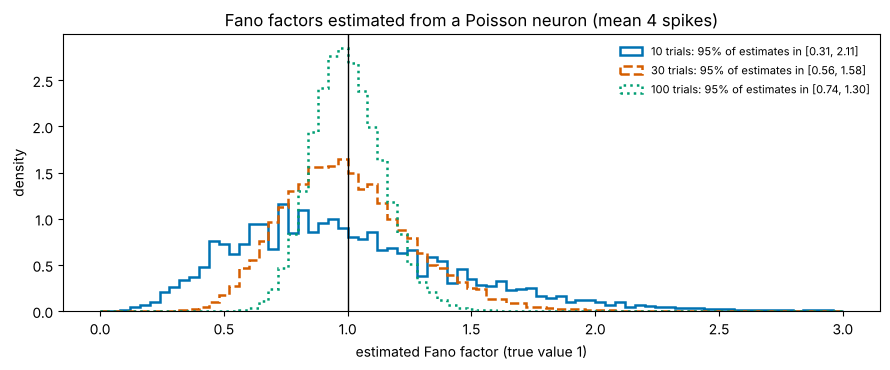

In [11]:
n_rep = 20000
for n in [5, 20, 80]:
    samples = RNG.poisson(4.0, size=(n_rep, n))                              # (20000, n): repeated experiments of n trials, true mean 4, variance 4
    means = samples.mean(axis=1)
    v_n, v_n1 = samples.var(axis=1, ddof=0), samples.var(axis=1, ddof=1)
    print(f"n = {n:>2}: SD of the sample mean {means.std():.3f} (theory sigma/sqrt(n) = {2 / np.sqrt(n):.3f});  "
          f"average variance estimate: divisor n {v_n.mean():.3f}, divisor n-1 {v_n1.mean():.3f} (true 4)")

ff_est = {}
for n in [10, 30, 100]:
    s = RNG.poisson(4.0, size=(n_rep, n))
    m = s.mean(axis=1)
    ff_est[n] = s.var(axis=1, ddof=1)[m > 0] / m[m > 0]
fig, ax = plt.subplots(figsize=(9, 3.8))
for (n, ff), c, ls in zip(ff_est.items(), PALETTE, LINESTYLES):
    lo, hi = np.percentile(ff, [2.5, 97.5])
    ax.hist(ff, bins=np.linspace(0, 3, 76), density=True, histtype='step', lw=1.8, color=c, ls=ls, label=f'{n} trials: 95% of estimates in [{lo:.2f}, {hi:.2f}]')
ax.axvline(1, color='black', lw=1)
ax.set_xlabel('estimated Fano factor (true value 1)'); ax.set_ylabel('density'); ax.set_title('Fano factors estimated from a Poisson neuron (mean 4 spikes)')
ax.legend(fontsize=8, frameon=False); plt.tight_layout(); plt.show()

With 10 trials, a perfectly Poisson neuron produces estimated Fano factors anywhere from about 0.3 to 2.1; with 100 trials, from about 0.75 to 1.3. A single neuron's FF of 1.4 from 20 trials is no evidence of "super-Poisson" variability. A population of neurons that **all** sit above 1, or a median well above the null spread, is.

#### Interactive version: number of trials

In [12]:
n_list = [5, 10, 20, 40, 80, 160, 320]
bins_f = np.linspace(0, 3, 61)
def ff_hist(n):
    s = np.random.default_rng(n).poisson(4.0, size=(5000, n))
    m = s.mean(axis=1)
    ff = s.var(axis=1, ddof=1)[m > 0] / m[m > 0]
    return np.histogram(ff, bins=bins_f, density=True)[0], np.percentile(ff, [2.5, 97.5])
h0, ci0 = ff_hist(n_list[0])
cf = 0.5 * (bins_f[1:] + bins_f[:-1])
fig_n = go.Figure([go.Bar(x=cf, y=np.round(h0, 4), marker_color=PALETTE[0], name='estimated FF')])
fr = []
for i, n in enumerate(n_list):
    h, ci = ff_hist(n)
    fr.append(go.Frame(name=str(i), data=[go.Bar(y=np.round(h, 4))], layout=go.Layout(title=f'{n} trials per estimate: 95% of Fano factors in [{ci[0]:.2f}, {ci[1]:.2f}] (true value 1)')))
fig_n.frames = fr
buttons, sliders = play_pause_and_slider(n_list, prefix='trials = ', duration=600)
fig_n.update_layout(title=fr[0].layout.title.text, xaxis=dict(title='estimated Fano factor'), yaxis=dict(title='density', range=[0, 5]),
                    template='plotly_white', width=850, height=480, updatemenus=buttons, sliders=sliders)
fig_n.show(config=PLOTLY_CONFIG)

# **Part 8: Mini-Lab — How Variable Are Real Neurons?**

### A. Interspike intervals of retinal ganglion cells
**Data.** Spike times of four parasol retinal ganglion cells (two OFF, two ON) from an isolated primate retina, stimulated for 20 minutes with full-field binary white noise ([Uzzell & Chichilnisky, 2004](https://doi.org/10.1152/jn.01171.2003)). The file `SpTimes.mat` is distributed with Jonathan Pillow's GLM tutorial ([pillowlab/GLMspiketraintutorial_python](https://github.com/pillowlab/GLMspiketraintutorial_python), MIT licence), whose data README asks that the recordings be used for tutorial purposes only; we download it at run time and do not redistribute it.

| Array | Shape | Meaning, units |
|---|---|---|
| `rgc_times[i]` | (n_spikes,) | spike times of cell $i$ (s), sorted |

The tutorial's README says the times are in stimulus frames, but the values run up to 1201, which matches 20 minutes **in seconds** (20 minutes of 120 Hz frames would be about 144,000 frames). We treat them as seconds, a check worth making on any downloaded dataset.

In [13]:
import os, urllib.request
from scipy.io import loadmat

RGC_FILE = 'SpTimes.mat'
if not os.path.exists(RGC_FILE):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/pillowlab/GLMspiketraintutorial_python/100d95a3ad6dc98304fbbb52545669cc385a124b/data_RGCs/SpTimes.mat', RGC_FILE)
rgc_raw = loadmat(RGC_FILE)['SpTimes']                                      # (1, 4) cell array
rgc_times = [np.sort(c.ravel().astype(float)) for c in rgc_raw.ravel()]    # 4 arrays of spike times (s)
rgc_names = ['OFF cell 1', 'OFF cell 2', 'ON cell 3', 'ON cell 4']
T_end = 1200.0                                                              # analyse the first 20 minutes
rgc_times = [t[t < T_end] for t in rgc_times]
print("largest spike time across cells:", max(t.max() for t in rgc_times).round(1), "s (consistent with a 20-minute recording in seconds)")
print(f"{'cell':<12}{'spikes':>8}{'rate (/s)':>10}{'mean ISI':>10}{'median':>9}{'SD':>8}{'CV':>6}{'skew':>6}{'ISIs < 3 ms':>13}{'1/E[T]':>9}{'E[1/T]':>9}")
isis_ms = []
for name, t in zip(rgc_names, rgc_times):
    isi = np.diff(t) * 1000                                                 # (n_spikes - 1,) ms
    isis_ms.append(isi)
    sk = np.mean((isi - isi.mean())**3) / isi.std()**3
    print(f"{name:<12}{t.size:>8}{t.size / T_end:>10.1f}{isi.mean():>10.1f}{np.median(isi):>9.1f}{isi.std(ddof=1):>8.1f}{isi_cv(t):>6.2f}{sk:>6.1f}"
          f"{np.mean(isi < 3):>13.3f}{1000 / isi.mean():>9.1f}{np.mean(1000 / isi):>9.1f}")

largest spike time across cells: 1200.0 s (consistent with a 20-minute recording in seconds)
cell          spikes rate (/s)  mean ISI   median      SD    CV  skew  ISIs < 3 ms   1/E[T]   E[1/T]
OFF cell 1     31492      26.2      38.1     11.8    49.7  1.30   1.7        0.065     26.2    130.7
OFF cell 2     21527      17.9      55.7     41.1    53.0  0.95   1.3        0.045     17.9     85.2
ON cell 3      49896      41.6      24.0      5.6    34.0  1.41   2.0        0.048     41.6    161.2
ON cell 4      43079      35.9      27.9      4.0    44.6  1.60   2.2        0.210     35.9    203.1


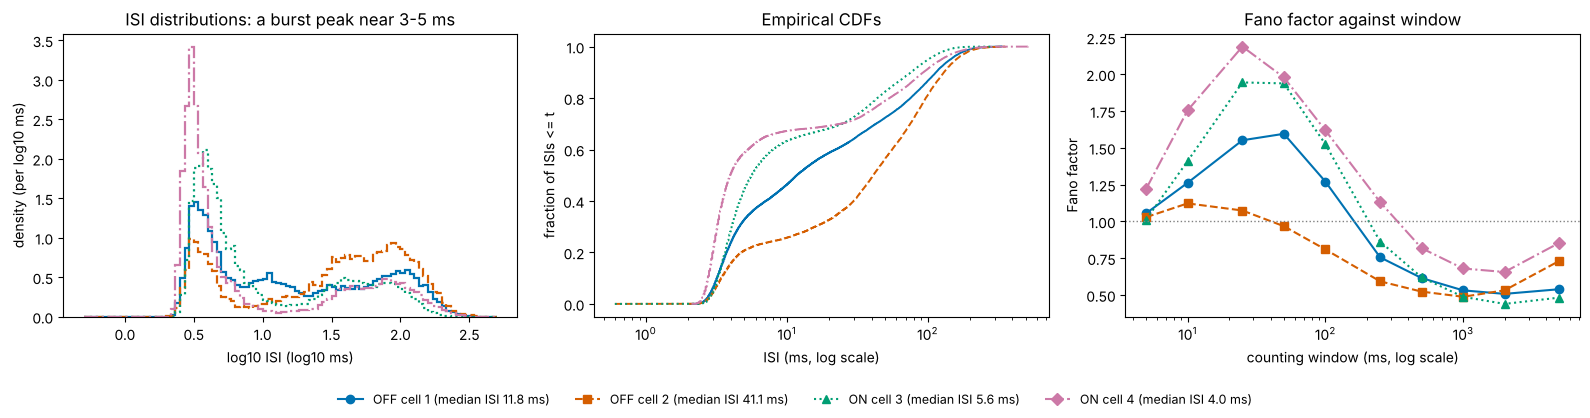

Fano factor at 10 ms / 50 ms / 1 s: {'OFF cell 1': (1.26, 1.6, 0.53), 'OFF cell 2': (1.12, 0.97, 0.49), 'ON cell 3': (1.41, 1.94, 0.49), 'ON cell 4': (1.75, 1.98, 0.68)}


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for i, (name, isi) in enumerate(zip(rgc_names, isis_ms)):
    axes[0].hist(np.log10(isi), bins=np.linspace(-0.3, 2.7, 91), density=True, histtype='step', lw=1.6, color=PALETTE[i], ls=LINESTYLES[i])
    srt = np.sort(isi)
    axes[1].step(srt, np.arange(1, srt.size + 1) / srt.size, where='post', color=PALETTE[i], ls=LINESTYLES[i], lw=1.4)
axes[0].set_xlabel('log10 ISI (log10 ms)'); axes[0].set_ylabel('density (per log10 ms)'); axes[0].set_title('ISI distributions: a burst peak near 3-5 ms')
axes[1].set_xscale('log'); axes[1].set_xlabel('ISI (ms, log scale)'); axes[1].set_ylabel('fraction of ISIs <= t'); axes[1].set_title('Empirical CDFs')
ff_rgc = np.array([[fano(t, w, 0, T_end) for w in windows] for t in rgc_times])   # (4, 10)
for i, name in enumerate(rgc_names):
    axes[2].semilogx(windows * 1000, ff_rgc[i], marker=MARKERS[i], color=PALETTE[i], ls=LINESTYLES[i], lw=1.5, label=f'{name} (median ISI {np.median(isis_ms[i]):.1f} ms)')
axes[2].axhline(1, color='grey', ls=':', lw=1)
axes[2].set_xlabel('counting window (ms, log scale)'); axes[2].set_ylabel('Fano factor'); axes[2].set_title('Fano factor against window')
fig.legend(*axes[2].get_legend_handles_labels(), loc='lower center', ncol=4, fontsize=9, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1]); plt.show()
print("Fano factor at 10 ms / 50 ms / 1 s:", {n: tuple(np.round(ff_rgc[i, [1, 3, 7]], 2).tolist()) for i, n in enumerate(rgc_names)})

**Reading the retinal cells.**
- **Firing rate is not the average of $1/\text{ISI}$.** OFF cell 1 fires 26 spikes/s, but the mean of its instantaneous rates $1/T$ is about 130 spikes/s, because half of its intervals are shorter than 12 ms. This is Part 3's $E[g(T)] \ne g(E[T])$ at full strength.
- **CV above 1 everywhere.** All four cells have bimodal interval distributions: a peak at 3-5 ms (spikes within a burst, limited below by refractoriness at about 2 ms) and a broad hump at tens of milliseconds (gaps between bursts). Mean ISIs far exceed medians, and CVs are 0.95-1.6.
- **The Fano factor depends on the window, and not monotonically.** At 25-50 ms windows, bursts push FF to 1.5-2.2 in three of the four cells (OFF cell 2, the least bursty, stays near 1); at windows of a second, FF falls well below 1 (0.5-0.7). Over long windows the white-noise stimulus, which is the same statistically from second to second, makes counts **more regular than Poisson**; over short windows, bursts make them **more variable**. A single "Fano factor of this neuron" does not exist.
- **Limits.** These are intervals pooled over a 20-minute, rapidly changing stimulus, so CV mixes intrinsic irregularity with stimulus-driven rate changes. A handful of intervals below 1 ms in two cells are below any plausible refractory period and are most likely spike-sorting artefacts: a reminder to look at the smallest values of any distribution.

### B. Trial-to-trial variability across a mouse brain
Now take repeated trials of the same condition: the 108 trials with **no grating** in the Lesson 16 session (Steinmetz et al., 2019, mouse Lederberg), spike counts 50-250 ms after stimulus onset. For every neuron with a mean of at least 1 spike per window on these trials, we compute the mean and variance of its count across trials: one Fano factor per neuron, with the window fixed at 200 ms.

In [15]:
STEIN_FILE = 'steinmetz_s11_lederberg.npz'
for cand in [STEIN_FILE, os.path.join('..', '..', 'data', STEIN_FILE)]:
    if os.path.exists(cand):
        stein_path = cand; break
else:
    urllib.request.urlretrieve('https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/8f9e0431a21d8ac0aa016e3502735f3b8627863a/data/' + STEIN_FILE, STEIN_FILE)
    stein_path = STEIN_FILE
dat = np.load(stein_path)
spk = dat['counts'].astype(float)                                          # (340, 698) spikes in 0.2 s
area = dat['brain_area']                                                   # (698,)
blank = (dat['contrast_left'] == 0) & (dat['contrast_right'] == 0)         # (340,) trials with no grating
X_b = spk[blank]                                                           # (108, 698): trials x neurons
mu_b, var_b = X_b.mean(axis=0), X_b.var(axis=0, ddof=1)                    # (698,) each, spikes and spikes^2
keep = mu_b >= 1.0
ff_b = var_b[keep] / mu_b[keep]                                            # (n_kept,) Fano factors
print(f"{blank.sum()} blank trials; {keep.sum()} of {spk.shape[1]} neurons have mean >= 1 spike per 200 ms")
print(f"Fano factors: median {np.median(ff_b):.2f}, quartiles {np.round(np.percentile(ff_b, [25, 75]), 2)}, fraction above 1: {np.mean(ff_b > 1):.2f}")

# Null spread: the same means, Poisson counts (true FF = 1), the same 108 trials.
null_draws = np.concatenate([(lambda s: s.var(axis=0, ddof=1) / np.maximum(s.mean(axis=0), 1e-12))(RNG.poisson(m, size=(blank.sum(), 20))) for m in mu_b[keep]])
print(f"Poisson neurons with the same means and 108 trials: 95% of FFs in {np.round(np.percentile(null_draws, [2.5, 97.5]), 2)};  "
      f"fraction above 1: {np.mean(null_draws > 1):.2f};  median {np.median(null_draws):.2f}")
by_area = {str(a): np.median(ff_b[area[keep] == a]) for a in np.unique(area[keep]) if np.sum(area[keep] == a) >= 8}
print("median FF by area (areas with >= 8 neurons):", {k: round(float(v), 2) for k, v in by_area.items()})

pop = X_b[:, keep].sum(axis=1)                                             # (108,) summed count of the kept neurons
cov_b = np.cov(X_b[:, keep], rowvar=False)
print(f"\nsummed population count: mean {pop.mean():.0f} spikes, variance {pop.var(ddof=1):.0f};  sum of individual variances {var_b[keep].sum():.0f};  "
      f"ratio {pop.var(ddof=1) / var_b[keep].sum():.1f}")
print(f"mean pairwise noise covariance {cov_b[~np.eye(keep.sum(), dtype=bool)].mean():.3f} spikes^2;  population Fano factor {pop.var(ddof=1) / pop.mean():.1f}")

108 blank trials; 162 of 698 neurons have mean >= 1 spike per 200 ms
Fano factors: median 1.50, quartiles [1.15 2.17], fraction above 1: 0.86


Poisson neurons with the same means and 108 trials: 95% of FFs in [0.76 1.29];  fraction above 1: 0.47;  median 0.99
median FF by area (areas with >= 8 neurons): {'DG': 1.57, 'MD': 2.01, 'SUB': 1.43, 'VISam': 1.21, 'root': 1.23}

summed population count: mean 433 spikes, variance 4555;  sum of individual variances 728;  ratio 6.3
mean pairwise noise covariance 0.147 spikes^2;  population Fano factor 10.5


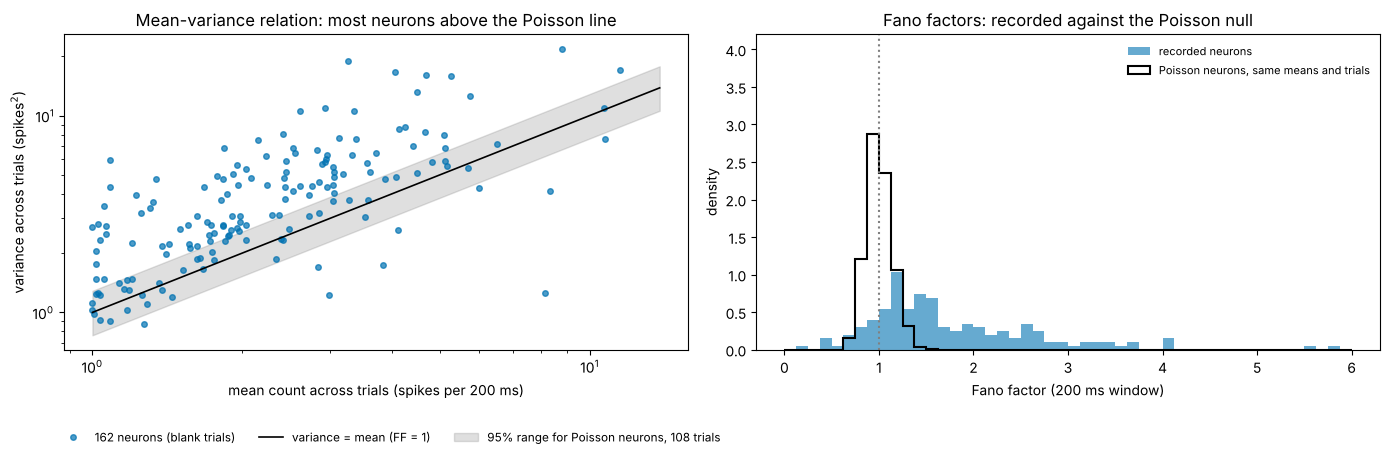

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].loglog(mu_b[keep], var_b[keep], 'o', color=PALETTE[0], ms=4, alpha=0.7, label=f'{keep.sum()} neurons (blank trials)')
mm = np.logspace(0, np.log10(mu_b[keep].max() * 1.2), 50)
axes[0].loglog(mm, mm, 'k-', lw=1.2, label='variance = mean (FF = 1)')
lo_n, hi_n = np.percentile(null_draws, [2.5, 97.5])
axes[0].fill_between(mm, lo_n * mm, hi_n * mm, color='grey', alpha=0.25, label='95% range for Poisson neurons, 108 trials')
axes[0].set_xlabel('mean count across trials (spikes per 200 ms)'); axes[0].set_ylabel('variance across trials (spikes$^2$)')
axes[0].set_title('Mean-variance relation: most neurons above the Poisson line'); 
axes[1].hist(ff_b, bins=np.linspace(0, 6, 49), density=True, color=PALETTE[0], alpha=0.6, label='recorded neurons')
axes[1].hist(null_draws, bins=np.linspace(0, 6, 49), density=True, histtype='step', color='black', lw=1.5, label='Poisson neurons, same means and trials')
axes[1].axvline(1, color='grey', ls=':')
axes[1].set_xlabel('Fano factor (200 ms window)'); axes[1].set_ylabel('density'); axes[1].set_title('Fano factors: recorded against the Poisson null'); axes[1].set_ylim(0, 4.2); axes[1].legend(fontsize=8, frameon=False, loc='upper right')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower left', bbox_to_anchor=(0.04, 0), ncol=3, fontsize=8.5, frameon=False)
plt.tight_layout(rect=[0, 0.09, 1, 1]); plt.show()

**Reading the mouse data.**
- **Most neurons are more variable than Poisson.** The median Fano factor across 162 neurons is about 1.5, and more than four in five exceed 1, while Poisson neurons with the same means and the same 108 trials would sit around 1 with about half above. Individual values carry wide sampling noise (Part 7), but the population shift is far outside it.
- **Variability is shared.** The summed count of these neurons varies about six times more than the sum of their individual variances would allow if they were independent: the many small positive covariances of Part 5 dominate. Shared fluctuations across trials (arousal, engagement, movement, slow drift over the session) raise every neuron's variance together.
- **Blank trials are not identical trials.** "Same stimulus" does not mean "same brain state". Part of the excess variance is the law of total probability at work: if the mean count depends on a hidden state $S$, then $\operatorname{Var}(N) = E[\operatorname{Var}(N \mid S)] + \operatorname{Var}(E[N \mid S])$ (the **law of total variance**), and the second term adds variance even when each state is Poisson.

**Limits.** One session; one 200 ms window; neurons with mean below 1 spike excluded (FF is very noisy for low counts); trials spread over the whole session, so slow drifts are included in "trial-to-trial" variability.

# **Part 9: Applications in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| PMF / PDF / CDF | spike-count and ISI distributions; reaction-time distributions; empirical CDFs for comparing conditions | output distributions of classifiers; likelihood models; quantile-based evaluation |
| Expectation, variance, moments | mean rates, response variability, skewed ISI and reaction-time distributions | loss as an expectation over data; batch statistics |
| $E[g(X)] \ne g(E[X])$ | mean rate vs mean instantaneous rate; averaging tuning curves across trials | Jensen's inequality behind variational bounds; averaging nonlinear predictions |
| Linear transformations, z-scores | unit changes (counts ↔ rates); z-scored responses for comparing neurons | feature standardisation; batch and layer normalisation |
| Nonlinear transformations | log ISIs, square-root transforms of counts | log-transformed targets; inverse-CDF sampling in simulation |
| Covariance, variance of a sum | noise correlations limit population averaging | covariance matrices, PCA, ensembles (averaging correlated models helps less) |
| CV and Fano factor | regularity of firing, bursting, cortical variability, variability quenching after stimulus onset | — (domain-specific measures of spiking models) |
| Sampling variability, $\sigma/\sqrt n$ | how many trials and neurons are needed | mini-batch gradient noise (Lesson 12); evaluation error bars |

# **Part 10: Summary, Exit Ticket and Lesson 18 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Random variable | number attached to each outcome | discrete (counts) or continuous (intervals) |
| PMF | $p(k) = P(X = k)$, $\sum_k p(k) = 1$ | `np.bincount(x, minlength=K) / n` |
| PDF | $P(a < X \le b) = \int_a^b f$ | a density, not a probability; units 1/(units of $x$); `density=True` |
| CDF | $F(x) = P(X \le x)$; $P(a < X \le b) = F(b) - F(a)$ | defined everywhere; median $= F^{-1}(0.5)$; empirical CDF needs no bins |
| Expectation | $\sum k\,p(k)$ or $\int x f(x)\,dx$; linear | $E[g(X)] \ne g(E[X])$ for nonlinear $g$ |
| Variance, SD | $E[(X - \mu)^2]$; $\sigma = \sqrt{\operatorname{Var}}$ | `ddof=1` for sample variance; SD in the units of $X$ |
| Linear transform | $E[aX + b] = a\mu + b$, $\operatorname{Var} = a^2\sigma^2$ | z-score: unitless, mean 0, SD 1 |
| Covariance | $E[XY] - \mu_X\mu_Y$; $\operatorname{Var}(\sum X_i) = \sum_{i,j}\operatorname{Cov}(X_i, X_j)$ | zero covariance ≠ independence; covariances dominate population variance |
| CV, Fano factor | $\mathrm{SD}(T)/E[T]$; $\operatorname{Var}(N)/E[N]$ | Poisson: 1 and 1; FF depends on the window; counts, not rates |
| Sampling variability | $\operatorname{SE}(\bar X) = \sigma/\sqrt n$ | every estimate (including FF and CV) has a spread |

**Exit ticket.** A study reports that neurons in area X have "a Fano factor of 1.3". List three facts you need before interpreting this number.

*(Suggested answer: the counting window (FF depends strongly on it); the number of trials and how the 1.3 was summarised (a single neuron's FF from 20 trials is consistent with 1; a median over hundreds of neurons is not), ideally with the null spread; whether trials were matched for stimulus and behavioural state (drifts and state changes inflate FF), and that counts, not rates, were used.)*

**Lesson 18 — Binomial, Poisson, Gaussian.** This lesson used the Poisson process as a reference without deriving it. Next we meet the three distributions that do most of the work in neural data analysis: the binomial for successes in trials, the Poisson for counts (with its mean–variance equality, which the Fano factor tests), and the Gaussian for sums and averages, together with the central limit theorem and a first look at likelihood.

**Further reading.** J. K. Blitzstein and J. Hwang, *Introduction to Probability*, 2nd ed. (2019), Chapters 3–7; P. Dayan and L. F. Abbott, *Theoretical Neuroscience* (2001), Chapter 1 (spike-train statistics, CV and Fano factor); M. M. Churchland et al., "Stimulus onset quenches neural variability", *Nature Neuroscience* 13 (2010); G. R. Holt et al., "Comparison of discharge variability in vitro and in vivo in cat visual cortex neurons", *Journal of Neurophysiology* 75 (1996).